--- Initial Data Preview ---


,movie_id,title,release_year,budget_m,revenue_m,runtime_min,rating,mpaa_rating
0,101,Interstellar,2014,165.0,730,169,8.7,PG-13
1,102,Gladiator,2000,103.0,465,155,8.5,R
2,103,The Matrix,1999,63.0,467,136,8.7,R
3,104,Whiplash,2014,3.3,49,106,8.5,R
4,105,Gravity,2013,100.0,723,91,7.7,PG-13



Dataset Shape: (6, 8)

--- Data Types ---
movie_id          int64
title            object
release_year      int64
budget_m        float64
revenue_m         int64
runtime_min       int64
rating          float64
mpaa_rating      object
dtype: object

--- Missing Values ---
movie_id        0
title           0
release_year    0
budget_m        0
revenue_m       0
runtime_min     0
rating          0
mpaa_rating     0
dtype: int64

--- Duplicate Rows ---
1

--- Cleaned & Transformed Data ---


,title,budget_m,revenue_m,net_profit_m,budget_tier
0,Interstellar,165.0,730,565.0,High Budget
1,Gladiator,103.0,465,362.0,Medium Budget
2,The Matrix,63.0,467,404.0,Medium Budget
3,Whiplash,3.3,49,45.7,Low Budget
4,Gravity,100.0,723,623.0,Medium Budget


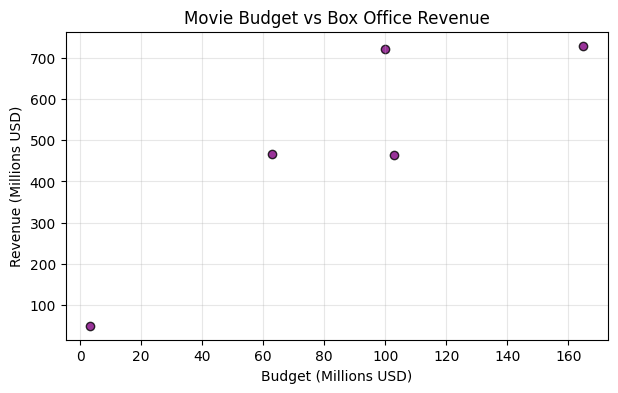

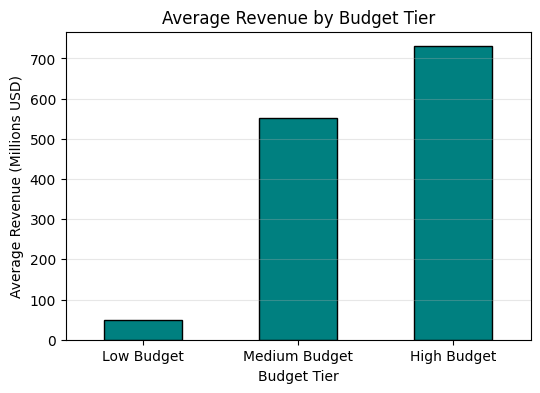

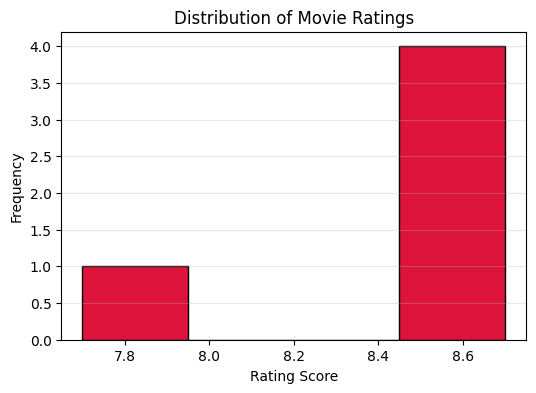

In [1]:
# ==========================================
# Blockbuster Movies Analysis Project
# Course: 2323 CIS - Introduction to Data Science
# ==========================================

# 1. Core Imports (Labs 1 & 2)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 50)

# 2. Load Unique Custom Dataset (Lab 3)
data = {
    'movie_id': [101, 102, 103, 104, 105, 105],
    'title': ['Interstellar', 'Gladiator', 'The Matrix', 'Whiplash', 'Gravity', 'Gravity'],
    'release_year': [2014, 2000, 1999, 2014, 2013, 2013],
    'budget_m': [165, 103, 63, 3.3, 100, 100],
    'revenue_m': [730, 465, 467, 49, 723, 723],
    'runtime_min': [169, 155, 136, 106, 91, 91],
    'rating': [8.7, 8.5, 8.7, 8.5, 7.7, 7.7],
    'mpaa_rating': ['PG-13', 'R', 'R', 'R', 'PG-13', 'PG-13']
}

df_movies = pd.DataFrame(data)
print("--- Initial Data Preview ---")
display(df_movies.head())

# 3. Data Understanding Section (Labs 1 & 5)
print("\nDataset Shape:", df_movies.shape)
print("\n--- Data Types ---")
print(df_movies.dtypes)
print("\n--- Missing Values ---")
print(df_movies.isna().sum())
print("\n--- Duplicate Rows ---")
print(df_movies.duplicated().sum())

# 4. Data Preparation and Cleaning Section (Labs 5 & 6)
# Remove duplicate rows
df_clean = df_movies.drop_duplicates().copy()

# Standardize text strings
df_clean['title'] = df_clean['title'].str.strip().str.title()

# Data Transformation: Calculate Net Profit
df_clean['net_profit_m'] = df_clean['revenue_m'] - df_clean['budget_m']

# Binning / Categorization (Budget Tiers)
bins = [0, 50, 150, 300]
labels = ['Low Budget', 'Medium Budget', 'High Budget']
df_clean['budget_tier'] = pd.cut(df_clean['budget_m'], bins=bins, labels=labels)

print("\n--- Cleaned & Transformed Data ---")
display(df_clean[['title', 'budget_m', 'revenue_m', 'net_profit_m', 'budget_tier']])

# 5. Visualizations Section (Labs 9 & 10)

# Visualization 1: Scatter Plot - Budget vs Revenue
plt.figure(figsize=(7, 4))
plt.scatter(df_clean['budget_m'], df_clean['revenue_m'], color='purple', edgecolor='black', alpha=0.8)
plt.title('Movie Budget vs Box Office Revenue')
plt.xlabel('Budget (Millions USD)')
plt.ylabel('Revenue (Millions USD)')
plt.grid(alpha=0.3)
plt.show()

# Visualization 2: Bar Plot - Average Revenue by Budget Tier
avg_rev_tier = df_clean.groupby('budget_tier', observed=False)['revenue_m'].mean()

plt.figure(figsize=(6, 4))
avg_rev_tier.plot(kind='bar', color='teal', edgecolor='black', rot=0)
plt.title('Average Revenue by Budget Tier')
plt.xlabel('Budget Tier')
plt.ylabel('Average Revenue (Millions USD)')
plt.grid(axis='y', alpha=0.3)
plt.show()

# Visualization 3: Histogram - Distribution of Movie Ratings
plt.figure(figsize=(6, 4))
plt.hist(df_clean['rating'], bins=4, color='crimson', edgecolor='black')
plt.title('Distribution of Movie Ratings')
plt.xlabel('Rating Score')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.3)
plt.show()
